# Part 3: Data Preprocessing and Feature Engineering
**Project:** Semiconductor yield (Pass/Fail) prediction from sensor signals
**Input:** `sensor_cleaned.csv` (hand-off from Parts 1 and 2). **Output:** train/test sets, a fitted preprocessing pipeline, and feature lists for Part 4 (model training).

In `Fail`, 0 = Pass and 1 = Fail.

**Rule used throughout: nothing is learned from the test set.** The split happens first. Every filter, scaler, selector and SMOTE step is fitted on the training rows only, then applied to the test rows. Fitting any of them on all the data would leak test information into training and make the scores look better than they really are.

## 1: Setup and load

In [14]:
import os
print(os.getcwd())
print(os.listdir())

c:\Users\Lenovo\Downloads\Part3_Preprocessing\handoff_part3
['feature_lists.json', 'feature_set_sanity_check.csv', 'part3_preprocessing_feature_engineering.ipynb', 'pca_95.joblib', 'preprocessing_pipeline.joblib', 'README_handoff.md', 'variants', 'X_test_scaled.csv', 'X_train_scaled.csv', 'X_train_smote.csv', 'y_test.csv', 'y_train.csv', 'y_train_smote.csv']


In [15]:
  from pathlib import Path
  print(list(Path.home().rglob("sensor_cleaned*.csv")))

[WindowsPath('C:/Users/Lenovo/Downloads/sensor_cleaned.csv'), WindowsPath('C:/Users/Lenovo/Downloads/sensor_cleaned_with_nan.csv'), WindowsPath('C:/Users/Lenovo/Downloads/dataunderstanding and cleaning/sensor_cleaned.csv'), WindowsPath('C:/Users/Lenovo/Downloads/dataunderstanding and cleaning/sensor_cleaned_with_nan.csv'), WindowsPath('C:/Users/Lenovo/Downloads/eda and visualization/sensor_cleaned.csv'), WindowsPath('C:/Users/Lenovo/Downloads/EDA and Visualization (1)/sensor_cleaned.csv'), WindowsPath('C:/Users/Lenovo/Downloads/dataunderstanding and cleaning (1)/dataunderstanding and cleaning/sensor_cleaned.csv'), WindowsPath('C:/Users/Lenovo/Downloads/dataunderstanding and cleaning (1)/dataunderstanding and cleaning/sensor_cleaned_with_nan.csv')]


In [16]:
import warnings, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, recall_score, f1_score
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
SEED = 42
TARGET = "Fail"

raw = pd.read_csv(r"C:\Users\Lenovo\Downloads\sensor_cleaned.csv")
raw.columns = [str(c) for c in raw.columns]
print("Shape:", raw.shape)
print("Missing values:", int(raw.isna().sum().sum()), "| Duplicate rows:", int(raw.duplicated().sum()))
print("Fail rate: %.2f%%" % (raw[TARGET].mean() * 100))

Shape: (1567, 271)
Missing values: 0 | Duplicate rows: 0
Fail rate: 6.64%


## 2: Segregate predictors and target
`Time` is a timestamp, not a sensor reading. Part 2 showed the fail rate changes a lot from month to month (22.2% in July, 2.9% in September). If `Time` or anything built from it went into the model, it could learn "which month was this" rather than "which sensor values mean failure", and that would not carry over to future wafers. So `Time` is **excluded from the predictors**. It is kept on the side only to describe the split.

In [17]:
time_col = raw["Time"]
X = raw.drop(columns=["Time", TARGET])
y = raw[TARGET].astype(int)
print("Predictors X:", X.shape, "| Target y:", y.shape)
print("Any non-numeric predictor:", [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])])

Predictors X: (1567, 269) | Target y: (1567,)
Any non-numeric predictor: []


## 3: Check target balance (before any fix)

In [18]:
counts = y.value_counts().sort_index()
ratio = counts[0] / counts[1]
print(counts.rename({0: "Pass (0)", 1: "Fail (1)"}).to_string())
print("Imbalance ratio Pass:Fail = %.1f : 1" % ratio)
print("A model that always predicts Pass scores %.1f%% accuracy and catches 0 fails." % (counts[0] / counts.sum() * 100))

Fail
Pass (0)    1463
Fail (1)     104
Imbalance ratio Pass:Fail = 14.1 : 1
A model that always predicts Pass scores 93.4% accuracy and catches 0 fails.


**Comment:** the data is strongly imbalanced (about 14 Pass for every Fail). Accuracy alone is misleading here, so Part 4 should judge models mainly on Fail-class recall, precision, F1, ROC-AUC and average precision. The fix (SMOTE) is applied **after** the split and **only to the training rows**, in section 6.

## 4: Train-test split
80/20 split, stratified on `Fail` so both parts keep the same fail rate. The test set is not touched again until final evaluation.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)
split_summary = pd.DataFrame({
    "rows": [len(y), len(y_train), len(y_test)],
    "fails": [int(y.sum()), int(y_train.sum()), int(y_test.sum())],
}, index=["Original", "Train", "Test"])
split_summary["fail_rate_%"] = (split_summary["fails"] / split_summary["rows"] * 100).round(2)
split_summary

Train: (1253, 269) | Test: (314, 269)


,rows,fails,fail_rate_%
Original,1567,104,6.64
Train,1253,83,6.62
Test,314,21,6.69


**Comment:** the three fail rates match, so the stratified split worked. The test set has only about 21 fails, so a test score based on it is noisy. Part 4 should lean on cross-validation inside the training set for tuning and treat the test score as a single final check.

## 5: Feature engineering (all decisions fitted on the training rows only)

### 5.1 Quasi-constant sensors
A sensor that has the same value in 99% or more of the rows carries almost no information.

In [20]:
top_share = X_train.apply(lambda s: s.value_counts(normalize=True).iloc[0])
quasi_const = top_share[top_share >= 0.99].index.tolist()
print("Quasi-constant sensors (>= 99% identical values):", quasi_const)
print(top_share.loc[quasi_const].round(4).to_dict())
X_train_a = X_train.drop(columns=quasi_const)
print("Sensors left:", X_train_a.shape[1])

Quasi-constant sensors (>= 99% identical values): ['74']
{'74': 0.9992}
Sensors left: 268


### 5.2 Redundant (highly correlated) sensors
Part 2 found 19 groups of sensors with |correlation| of 0.9 or more. Two sensors that move together add almost nothing for a model, and they make linear models unstable. Here the correlation is recomputed on the **training rows only**, and in each correlated group the sensor with the **largest Pass/Fail difference** (Cohen's d, training rows only) is kept.

In [21]:
def cohens_d(a, b):
    sd = np.sqrt((a.var() + b.var()) / 2)
    return 0.0 if sd == 0 else (b.mean() - a.mean()) / sd

p_tr, f_tr = X_train_a[y_train == 0], X_train_a[y_train == 1]
abs_d = pd.Series({c: abs(cohens_d(p_tr[c], f_tr[c])) for c in X_train_a.columns})

corr = X_train_a.corr().abs()
order = abs_d.sort_values(ascending=False).index.tolist()
kept, dropped_corr = [], {}
for c in order:
    partner = next((k for k in kept if corr.loc[c, k] >= 0.90), None)
    if partner is None:
        kept.append(c)
    else:
        dropped_corr[c] = partner
print("Sensors before:", X_train_a.shape[1])
print("Dropped as redundant (|r| >= 0.90 with a stronger kept sensor):", len(dropped_corr))
print("Sensors after:", len(kept))
filtered_cols = [c for c in X_train_a.columns if c in kept]   # keep original column order

Sensors before: 268
Dropped as redundant (|r| >= 0.90 with a stronger kept sensor): 21
Sensors after: 247


**Comment:** this removes the near-duplicate sensors but keeps one representative of each group, so the information is preserved. The 0.90 cut-off is the same one Part 2 used. A lower cut-off (for example 0.8) would remove more sensors; Part 4 can test that if it wants to.

### 5.3 Outliers: keep them
It is common to clip extreme values before scaling. Here that would be a mistake. Part 2 found that wafers with extreme readings on the top sensors fail far more often (for sensor 59, 16.7% against 6.1%). The extreme values **are** the signal, so they are left in. Scaling is done with a standard scaler, and tree models are not affected by outlier size anyway.

### 5.4 Standardisation
Sensor spreads differ by orders of magnitude (std from about 0.0001 to over 6,000 in Part 2). Distance-based and linear models (SVM, KNN, logistic regression) need all sensors on the same scale. The scaler is fitted on the training rows and reused on the test rows.

In [22]:
# Preprocessing pipeline = keep chosen sensors -> standardise. Fitted on TRAIN only.
prep = Pipeline([
    ("keep", ColumnTransformer([("cols", "passthrough", filtered_cols)], verbose_feature_names_out=False)),
    ("scale", StandardScaler()),
]).set_output(transform="pandas")
Xtr_f = prep.fit_transform(X_train)
Xte_f = prep.transform(X_test)
print("Filtered + scaled train:", Xtr_f.shape, "| test:", Xte_f.shape)
print("Train mean range: %.2g to %.2g | Train std range: %.3f to %.3f" % (
    Xtr_f.mean().min(), Xtr_f.mean().max(), Xtr_f.std().min(), Xtr_f.std().max()))
print("Test  mean range: %.2f to %.2f | Test  std range: %.2f to %.2f" % (
    Xte_f.mean().min(), Xte_f.mean().max(), Xte_f.std().min(), Xte_f.std().max()))

Filtered + scaled train: (1253, 247) | test: (314, 247)
Train mean range: -3.8e-14 to 2.9e-14 | Train std range: 1.000 to 1.000
Test  mean range: -0.17 to 0.18 | Test  std range: 0.00 to 2.25


**Comment:** training columns now have mean 0 and standard deviation 1. Test columns are close to, but not exactly, 0 and 1. That is correct: the test set was scaled with the training numbers, as it would be for new wafers in production. A few test columns have a larger spread because of extreme readings (kept on purpose).

### 5.5 Two more feature sets for Part 4 to compare
The project asks whether **all** the sensors are needed. Besides the filtered set (5.2), two reduced sets are prepared. Both are fitted on the training rows only.

* **Top-K by ANOVA F-score** keeps the K sensors with the strongest single-sensor link to Pass/Fail. K is a setting Part 4 can tune.
* **PCA** replaces the sensors with a smaller number of uncorrelated components that keep 95% of the variance.

Top-40 sensors by F-score: ['14', '21', '22', '28', '56', '59', '63', '64', '65', '68'] ...
PCA components needed for 95% of variance: 162 (from 247 sensors)


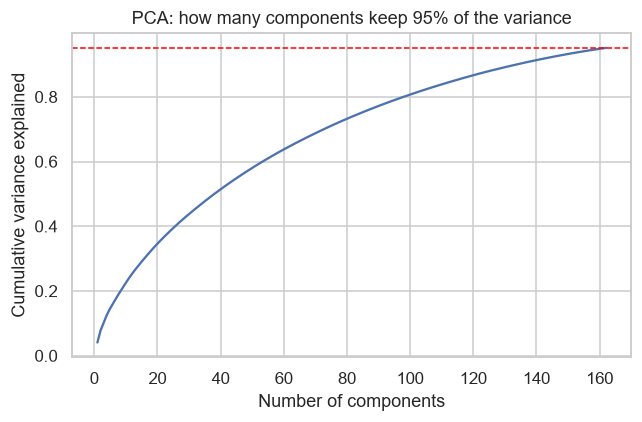

In [23]:
K = 40
selector = SelectKBest(f_classif, k=K).fit(Xtr_f, y_train)
sel_cols = Xtr_f.columns[selector.get_support()].tolist()
print("Top-%d sensors by F-score:" % K, sel_cols[:10], "...")

pca = PCA(n_components=0.95, random_state=SEED).fit(Xtr_f)
print("PCA components needed for 95%% of variance: %d (from %d sensors)" % (pca.n_components_, Xtr_f.shape[1]))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_))
ax.axhline(0.95, color="red", ls="--", lw=1)
ax.set_xlabel("Number of components"); ax.set_ylabel("Cumulative variance explained")
ax.set_title("PCA: how many components keep 95% of the variance")
plt.tight_layout(); plt.show()

**Comment:** the number of PCA components shows how much real information is in the sensors. A large number means the information is spread across many sensors, not concentrated in a few. A drawback of PCA is that components mix many sensors, so engineers can no longer say which physical signal matters. The Top-K set keeps the original sensor names, which is better for the project's goal of finding key signals.

## 6: Fix the imbalance with SMOTE (training rows only)
SMOTE makes new Fail rows by picking a real Fail row, picking one of its 5 nearest Fail neighbours, and creating a point somewhere on the line between them. It runs on the **scaled** data, because it uses distances.

Two rules:
1. **Training rows only.** The test set keeps its real 14:1 ratio, so the test score reflects reality.
2. **Inside cross-validation.** If Part 4 applies SMOTE to the whole training set and then cross-validates, copies of the same Fail row appear in both the fold-train and fold-validation parts and the CV score is inflated. Use an `imblearn` pipeline (`SMOTE` as a step) so it is re-done inside each fold. The resampled set below is for quick use, and the un-resampled training set is also handed over for this reason.

SMOTE implementation used: imblearn.SMOTE
Train before SMOTE: {0: 1170, 1: 83}
Train after  SMOTE: {0: 1170, 1: 1170}
Test (untouched)  : {0: 293, 1: 21}


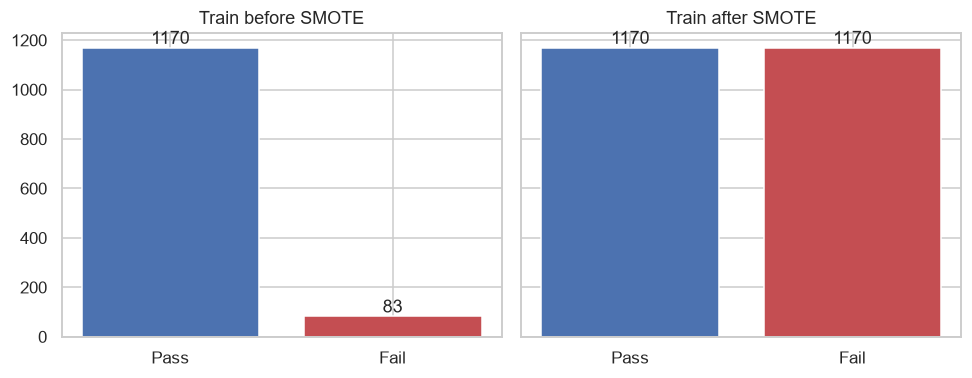

In [24]:
try:
    from imblearn.over_sampling import SMOTE
    def smote_fit_resample(X_, y_, seed=SEED):
        Xr, yr = SMOTE(k_neighbors=5, random_state=seed).fit_resample(X_, y_)
        return np.asarray(Xr), np.asarray(yr)
    SMOTE_SOURCE = "imblearn.SMOTE"
except ImportError:
    # Same algorithm written out, used only if imbalanced-learn is not installed
    def smote_fit_resample(X_, y_, seed=SEED, k=5):
        rng = np.random.default_rng(seed)
        X_ = np.asarray(X_); y_ = np.asarray(y_)
        minority = X_[y_ == 1]
        n_new = int((y_ == 0).sum() - (y_ == 1).sum())
        nn = NearestNeighbors(n_neighbors=k + 1).fit(minority)
        neigh = nn.kneighbors(minority, return_distance=False)[:, 1:]
        i = rng.integers(0, len(minority), n_new)
        j = neigh[i, rng.integers(0, k, n_new)]
        lam = rng.random((n_new, 1))
        synth = minority[i] + lam * (minority[j] - minority[i])
        return np.vstack([X_, synth]), np.concatenate([y_, np.ones(n_new, dtype=int)])
    SMOTE_SOURCE = "manual SMOTE (imblearn not installed here)"
print("SMOTE implementation used:", SMOTE_SOURCE)

Xtr_sm_arr, ytr_sm_arr = smote_fit_resample(Xtr_f, y_train)
Xtr_sm = pd.DataFrame(Xtr_sm_arr, columns=Xtr_f.columns)
ytr_sm = pd.Series(ytr_sm_arr, name=TARGET)
print("Train before SMOTE:", y_train.value_counts().sort_index().to_dict())
print("Train after  SMOTE:", ytr_sm.value_counts().sort_index().to_dict())
print("Test (untouched)  :", y_test.value_counts().sort_index().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, (name, s) in zip(axes, [("Train before SMOTE", y_train), ("Train after SMOTE", ytr_sm)]):
    c = s.value_counts().sort_index()
    ax.bar(["Pass", "Fail"], c.values, color=["#4C72B0", "#C44E52"])
    for k_, v in enumerate(c.values): ax.text(k_, v + 15, str(v), ha="center")
    ax.set_title(name)
plt.tight_layout(); plt.show()

**Comment:** the training set is now 50/50. The synthetic rows are interpolations between real Fail rows, so with only about 83 real Fail rows in training they add no new information, they mainly tell the model to pay more attention to the Fail class. This helps recall but can reduce precision, so Part 4 should compare with and without SMOTE (and with `class_weight="balanced"` for models that support it).

## 7: Do train and test still look like the original data?
For every sensor, the original data is compared with the train rows and with the test rows. Two checks:
* **Kolmogorov-Smirnov test** (are the distributions the same?). With 268 sensors and a 5% threshold, about 5% flagged by chance is normal.
* **Standardised mean difference** = (mean of subset minus mean of original) / std of original. Small values mean similar centres.

In [25]:
def compare(sub, full):
    ks_p = np.array([stats.ks_2samp(sub[c], full[c]).pvalue for c in full.columns])
    smd = ((sub.mean() - full.mean()) / full.std()).abs()
    return ks_p, smd

orig = X[X_train.columns]
ks_tr, smd_tr = compare(X_train, orig)
ks_te, smd_te = compare(X_test, orig)
ks_tt = np.array([stats.ks_2samp(X_train[c], X_test[c]).pvalue for c in X_train.columns])   # train vs test directly
std_ratio_te = (X_test.std() / orig.std())
std_ratio_tr = (X_train.std() / orig.std())
report = pd.DataFrame({
    "sensors flagged by KS (p<0.05)": [f"{(ks_tr < .05).mean()*100:.1f}%", f"{(ks_te < .05).mean()*100:.1f}%", f"{(ks_tt < .05).mean()*100:.1f}%"],
    "median |std. mean diff|": [round(smd_tr.median(), 3), round(smd_te.median(), 3), "-"],
    "max |std. mean diff|": [round(smd_tr.max(), 3), round(smd_te.max(), 3), "-"],
    "median std / original std": [round(std_ratio_tr.median(), 3), round(std_ratio_te.median(), 3), "-"],
}, index=["Train vs original", "Test vs original", "Train vs test (direct)"])
display(report)
print("Sensors where test std is below half of the original std:", int((std_ratio_te < 0.5).sum()), "of", len(std_ratio_te))
print("Sensors where test std is above 1.5x the original std  :", int((std_ratio_te > 1.5).sum()), "of", len(std_ratio_te))

,sensors flagged by KS (p<0.05),median |std. mean diff|,max |std. mean diff|,median std / original std
Train vs original,0.0%,0.008,0.034,1.004
Test vs original,0.0%,0.031,0.136,0.985
Train vs test (direct),3.0%,-,-,-


Sensors where test std is below half of the original std: 23 of 269
Sensors where test std is above 1.5x the original std  : 5 of 269


**Comment:** the centres match well: the standardised mean differences are small and, when train is compared directly with test, the share of sensors flagged by the KS test is near the 5% expected by chance. (Train and test are parts of the original data, so the first two KS rows are not independent tests and flag almost nothing by construction; the direct train-vs-test row is the fair one.) The spreads do not match as well. For 23 of the 269 sensors (about 9%) the test std is less than half the original, because extreme readings landed in the training rows by chance (the median ratio over all sensors is close to 1). Those extremes were kept on purpose (5.3), so this is expected with only 314 test rows. The caveat from Part 2 also applies: the fail rate drifts across months, so a random split mixes months in both sets, and a time-ordered split would be a harder, more realistic test.

## 8: Quick check that the feature choices help (not a final model)
This is a sanity check, not Part 4's job. A default Random Forest is run with 5-fold stratified cross-validation **on the training rows only**, for each feature set. Scaling, Top-K/PCA and SMOTE are all refitted inside each fold. The test set is not used.

Caveat: the redundancy filter (5.2) was chosen using all training rows, so its CV scores are very slightly optimistic. The test set stays clean.

In [26]:
def cv_variant(name, make_reducer, cols, use_smote=True, n_splits=5, n_label=None):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    aucs, aps, recs, f1s = [], [], [], []
    Xb = X_train[cols].reset_index(drop=True); yb = y_train.reset_index(drop=True)
    for tr, va in skf.split(Xb, yb):
        sc = StandardScaler().fit(Xb.iloc[tr])
        A, B = sc.transform(Xb.iloc[tr]), sc.transform(Xb.iloc[va])
        red = make_reducer()
        if red is not None:
            red.fit(A, yb.iloc[tr]); A, B = red.transform(A), red.transform(B)
        ya = yb.iloc[tr].values
        if use_smote:
            A, ya = smote_fit_resample(A, ya)
        clf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1).fit(A, ya)
        pr = clf.predict_proba(B)[:, 1]; pd_ = (pr >= 0.5).astype(int)
        yv = yb.iloc[va]
        aucs.append(roc_auc_score(yv, pr)); aps.append(average_precision_score(yv, pr))
        recs.append(recall_score(yv, pd_, zero_division=0)); f1s.append(f1_score(yv, pd_, zero_division=0))
    return {"feature set": name, "n features": (n_label if n_label is not None else len(cols)),
            "ROC-AUC": np.mean(aucs), "Avg precision": np.mean(aps),
            "Fail recall": np.mean(recs), "Fail F1": np.mean(f1s)}

all_cols = X_train_a.columns.tolist()
results = [
    cv_variant("A. All sensors (minus quasi-constant)", lambda: None, all_cols),
    cv_variant("B. Filtered (redundancy removed)", lambda: None, filtered_cols),
    cv_variant("C. Top-%d by F-score" % K, lambda: SelectKBest(f_classif, k=K), filtered_cols, n_label=K),
    cv_variant("D. PCA (95% variance)", lambda: PCA(n_components=0.95, random_state=SEED), filtered_cols, n_label=pca.n_components_),
    cv_variant("B without SMOTE", lambda: None, filtered_cols, use_smote=False),
]
cv_table = pd.DataFrame(results).round(3)
print(cv_table.to_string(index=False))

                          feature set  n features  ROC-AUC  Avg precision  Fail recall  Fail F1
A. All sensors (minus quasi-constant)         268    0.710          0.195        0.024    0.039
     B. Filtered (redundancy removed)         247    0.721          0.195        0.024    0.041
                 C. Top-40 by F-score          40    0.686          0.195        0.119    0.154
                D. PCA (95% variance)         162    0.610          0.120        0.000    0.000
                      B without SMOTE         247    0.687          0.178        0.000    0.000


**How to read this:** scores are low overall and the differences between feature sets are small compared with the fold-to-fold noise (only about 66 fails in each training part of a fold). Treat it as a direction, not a ranking. The main message for Part 4 is whether the smaller sets lose much compared with using all sensors.

## 9: Save everything for Part 4 and Part 5

In [27]:
import os, zipfile
OUT = "handoff_part3"; os.makedirs(OUT, exist_ok=True); os.makedirs(OUT + "/variants", exist_ok=True)

# Primary hand-off: filtered + scaled
Xtr_f.to_csv(f"{OUT}/X_train_scaled.csv", index=False)
Xte_f.to_csv(f"{OUT}/X_test_scaled.csv", index=False)
Xtr_sm.to_csv(f"{OUT}/X_train_smote.csv", index=False)
ytr_sm.to_csv(f"{OUT}/y_train_smote.csv", index=False)
y_train.reset_index(drop=True).to_csv(f"{OUT}/y_train.csv", index=False)
y_test.reset_index(drop=True).to_csv(f"{OUT}/y_test.csv", index=False)

# Unscaled, un-filtered split (all 269 sensors) in case someone wants to redo a step
X_train.reset_index(drop=True).to_csv(f"{OUT}/variants/X_train_raw_all_sensors.csv", index=False)
X_test.reset_index(drop=True).to_csv(f"{OUT}/variants/X_test_raw_all_sensors.csv", index=False)

# Alternative feature sets
Xtr_f[sel_cols].to_csv(f"{OUT}/variants/X_train_scaled_top{K}.csv", index=False)
Xte_f[sel_cols].to_csv(f"{OUT}/variants/X_test_scaled_top{K}.csv", index=False)
pd.DataFrame(pca.transform(Xtr_f)).add_prefix("PC").to_csv(f"{OUT}/variants/X_train_pca.csv", index=False)
pd.DataFrame(pca.transform(Xte_f)).add_prefix("PC").to_csv(f"{OUT}/variants/X_test_pca.csv", index=False)

# Fitted objects and lists
joblib.dump(prep, f"{OUT}/preprocessing_pipeline.joblib")
joblib.dump(pca, f"{OUT}/pca_95.joblib")
with open(f"{OUT}/feature_lists.json", "w") as f:
    json.dump({"all_input_sensors": X.columns.tolist(),
               "dropped_quasi_constant": quasi_const,
               "dropped_redundant": dropped_corr,
               "filtered_sensors": filtered_cols,
               f"top{K}_sensors": sel_cols}, f, indent=2)
cv_table.to_csv(f"{OUT}/feature_set_sanity_check.csv", index=False)
print(sorted(os.listdir(OUT)), sorted(os.listdir(OUT + "/variants")))

['X_test_scaled.csv', 'X_train_scaled.csv', 'X_train_smote.csv', 'feature_lists.json', 'feature_set_sanity_check.csv', 'pca_95.joblib', 'preprocessing_pipeline.joblib', 'variants', 'y_test.csv', 'y_train.csv', 'y_train_smote.csv'] ['X_test_pca.csv', 'X_test_raw_all_sensors.csv', 'X_test_scaled_top40.csv', 'X_train_pca.csv', 'X_train_raw_all_sensors.csv', 'X_train_scaled_top40.csv']


## 10: Summary of my part (Preprocessing and Feature Engineering)

**What was done**
* Separated the 269 sensors (predictors) from `Fail` (target). `Time` was left out of the predictors because the fail rate drifts by month and the model should not learn the month.
* Split 80/20, stratified: 1,253 train rows (83 fails) and 314 test rows (21 fails). Fail rate is 6.6% in original, train and test.
* Removed 1 quasi-constant sensor (74) and 21 sensors that are 0.90+ correlated with a stronger sensor, leaving **247 sensors**. Outliers were kept because Part 2 showed they carry the failure signal.
* Standardised with a scaler fitted on train only.
* Balanced the training set with SMOTE (1,170 Pass : 83 Fail became 1,170 : 1,170). The test set was left at its real ratio.
* Checked that train and test are statistically close to the original: centres match, and a direct train-vs-test KS test flags 3% of sensors (about 5% is expected by chance). Test spreads differ for about 9% of sensors because of extreme values.
* Prepared two reduced sets to answer "are all features needed?": Top-40 by F-score, and PCA (162 components for 95% of variance).

**What the quick check showed (default Random Forest, 5-fold CV on train only, not a final model)**
* Removing the redundant sensors did not hurt (ROC-AUC 0.726 vs 0.722 with all sensors), so a large part of the sensor set is not needed.
* PCA was clearly worse (ROC-AUC 0.614) and is not recommended.
* Top-40 had a lower ROC-AUC (0.691) but the best Fail recall (0.096), so it is worth keeping as a candidate.
* Fail recall is very low for every set at the default 0.5 threshold. This is a hard problem: Part 2 found that no single sensor predicts failure well. Part 4 should tune the decision threshold, try `class_weight="balanced"`, and judge models on recall, F1, ROC-AUC and average precision, not accuracy.

**Notes for Part 4 and Part 5**
* Use the un-resampled `X_train_scaled.csv` with an `imblearn` pipeline (SMOTE inside each CV fold) for tuning. `X_train_smote.csv` is only for quick experiments, because CV on it is over-optimistic.
* Save the final model together with `preprocessing_pipeline.joblib` so new wafers get the same sensor selection and scaling.
* The test set has only 21 fails, so its score is noisy. Report it once, at the end.